In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense

Dataset shape: (17544,)
Missing values: 0


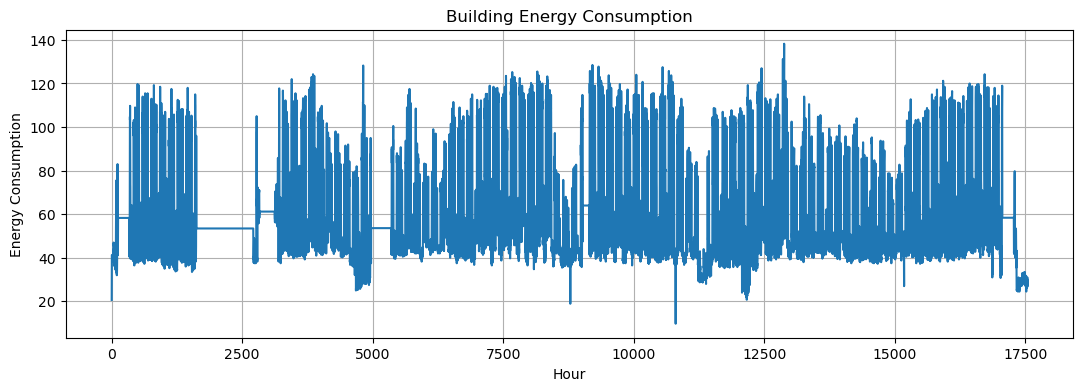

In [31]:
# Load dataset
df = pd.read_csv(
    r"C:\Users\ENG Hassan\OneDrive\Desktop\thesis\electricity_cleaned.csv"
)

# Select energy consumption
data = df['Robin_office_Gayle'].values

# Check dataset
print("Dataset shape:", data.shape)
print("Missing values:", np.isnan(data).sum())

plt.figure(figsize=(13, 4))
plt.plot(data)
plt.title("Building Energy Consumption")
plt.xlabel("Hour")
plt.ylabel("Energy Consumption")
plt.grid()
plt.show()

In [33]:
# Train-Test Split
split = int(len(data) * 0.8)

train_data = data[:split]

# Normalize data
scaler = MinMaxScaler()

scaler.fit(train_data.reshape(-1, 1))

scaled_data = scaler.transform(data.reshape(-1, 1))

print("Training samples:", split)
print("Testing samples:", len(data) - split)

Training samples: 14035
Testing samples: 3509


In [35]:
# Sequence length
window_size = 24

X_train, y_train = [], []
X_test, y_test = [], []

for i in range(window_size, len(scaled_data)):

    X = scaled_data[i-window_size:i]
    y = scaled_data[i]

    if i < split:
        X_train.append(X)
        y_train.append(y)
    else:
        X_test.append(X)
        y_test.append(y)

# Convert to arrays
X_train = np.array(X_train)
y_train = np.array(y_train)

X_test = np.array(X_test)
y_test = np.array(y_test)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (14011, 24, 1)
y_train: (14011, 1)
X_test: (3509, 24, 1)
y_test: (3509, 1)


In [37]:
# Build LSTM-GRU Model
model = Sequential([

    LSTM(32, return_sequences=True,
         input_shape=(window_size, 1)),

    GRU(16),

    Dense(1)

])

# Compile model
model.compile(
    optimizer='adam',
    loss='mse'
)

# Model summary
model.summary()

C:\Users\ENG Hassan\.matplotlib\new\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 16)             │         2,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,769 (26.44 KB)

 Trainable params: 6,769 (26.44 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
history = model.fit(

    X_train,
    y_train,

    epochs=20,
    batch_size=32,

    validation_split=0.1,

    shuffle=False,

    verbose=1
)

Epoch 1/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 0.0126 - val_loss: 0.0050
Epoch 2/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0036 - val_loss: 0.0028
Epoch 3/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0027 - val_loss: 0.0019
Epoch 4/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0022 - val_loss: 0.0017
Epoch 5/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0021 - val_loss: 0.0017
Epoch 6/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0020 - val_loss: 0.0018
Epoch 7/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0020 - val_loss: 0.0019
Epoch 8/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0019 - val_loss: 0.0019
Epoch 9/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0019 - val_loss: 0.0018
Epoch 10/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0019 - val_loss: 0.0017
Epoch 11/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0018 - val_loss: 0.0016
Epoch 12/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step

In [41]:
# Make predictions
predictions = model.predict(X_test)

# Inverse scaling
y_actual = scaler.inverse_transform(y_test)
y_pred = scaler.inverse_transform(predictions)

# Persistence baseline
baseline = scaler.inverse_transform(
    X_test[:, -1, :]
)

# Evaluation function
def evaluate(actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(mean_squared_error(actual, predicted))

    mape = np.mean(
        np.abs((actual - predicted) / np.maximum(np.abs(actual), 1e-8))
    ) * 100

    return mae, rmse, mape


# Evaluate both models
lstm_gru_results = evaluate(y_actual, y_pred)

baseline_results = evaluate(y_actual, baseline)

results = pd.DataFrame({

    'Model': ['Persistence', 'LSTM-GRU'],

    'MAE': [baseline_results[0], lstm_gru_results[0]],

    'RMSE': [baseline_results[1], lstm_gru_results[1]],

    'MAPE (%)': [baseline_results[2], lstm_gru_results[2]]

})

print(results.round(4))

110/110 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
         Model     MAE    RMSE  MAPE (%)
0  Persistence  4.0458  7.2002    6.6069
1     LSTM-GRU  3.0031  4.7492    5.2798


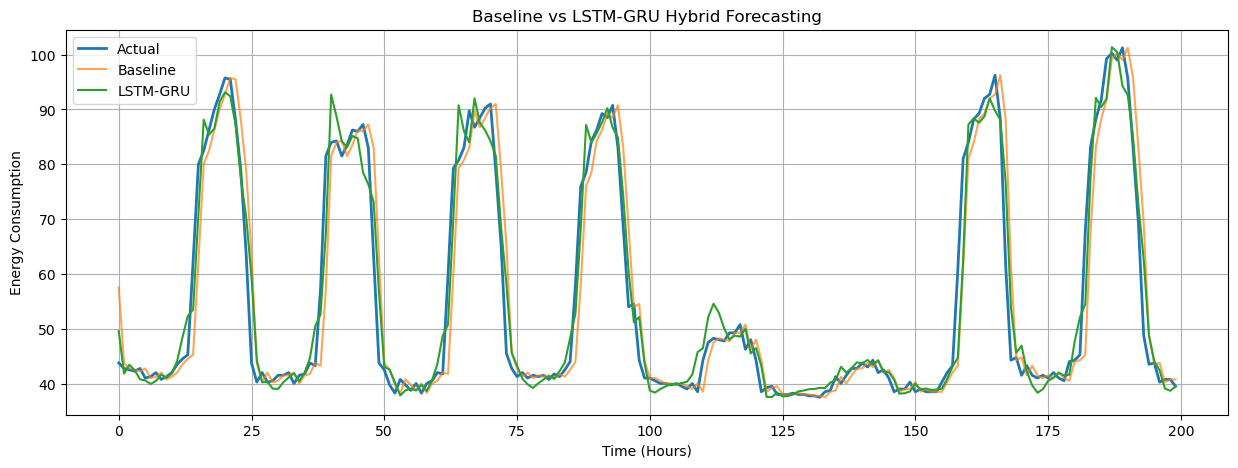

In [57]:
plt.figure(figsize=(15, 5))

plt.plot(y_actual[:200], label='Actual', linewidth=2)
plt.plot(baseline[:200], label='Baseline', alpha=0.7)
plt.plot(y_pred[:200], label='LSTM-GRU')


plt.title("Baseline vs LSTM-GRU Hybrid Forecasting")
plt.xlabel("Time (Hours)")
plt.ylabel("Energy Consumption")

plt.legend()
plt.grid()
plt.show()

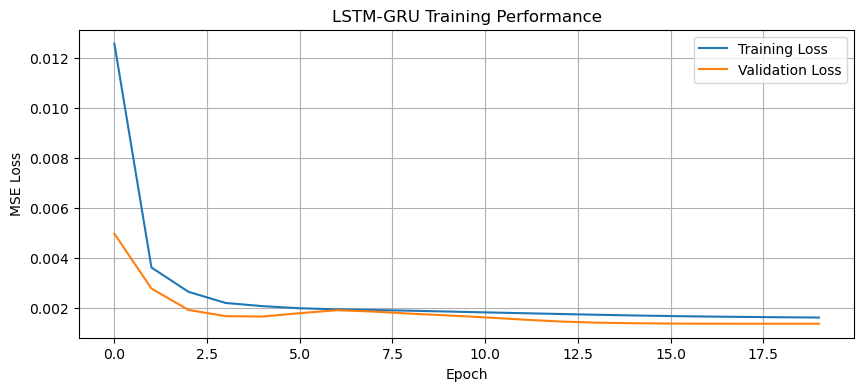

In [45]:
plt.figure(figsize=(10, 4))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("LSTM-GRU Training Performance")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid()

plt.show()

In [47]:
model.save("building_energy_lstm_gru.keras")

print("Model saved")

Model saved


In [49]:
# Get latest 24 hours
last_24_hours = scaled_data[-window_size:]

# Reshape input
next_input = last_24_hours.reshape(1, window_size, 1)

# Predict next hour
next_prediction = model.predict(next_input)

# Convert to original scale
next_prediction = scaler.inverse_transform(next_prediction)

print("Predicted Energy Consumption for Next Hour:",
      round(next_prediction[0][0], 4))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Predicted Energy Consumption for Next Hour: 30.1124


In [59]:
# Build LSTM Model
lstm_model = Sequential([

    LSTM(32, input_shape=(24, 1)),

    Dense(1)

])

# Compile
lstm_model.compile(
    optimizer='adam',
    loss='mse'
)

# Train
lstm_history = lstm_model.fit(

    X_train,
    y_train,

    epochs=20,
    batch_size=32,

    validation_split=0.1,

    shuffle=False,

    verbose=1
)

Epoch 1/20


C:\Users\ENG Hassan\.matplotlib\new\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


395/395 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0145 - val_loss: 0.0050
Epoch 2/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0040 - val_loss: 0.0035
Epoch 3/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0033 - val_loss: 0.0030
Epoch 4/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0029 - val_loss: 0.0027
Epoch 5/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0025 - val_loss: 0.0021
Epoch 6/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0023 - val_loss: 0.0019
Epoch 7/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0022 - val_loss: 0.0018
Epoch 8/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0021 - val_loss: 0.0017
Epoch 9/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0020 - val_loss: 0.0016
Epoch 10/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0020 - val_loss: 0.0016
Epoch 11/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0020 - val_loss: 0.0016
Epoch 12/20
395/395 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.

In [61]:
# LSTM Predictions
lstm_predictions = lstm_model.predict(X_test)

# Inverse Scaling
lstm_predictions = scaler.inverse_transform(
    lstm_predictions
)

lstm_actual = scaler.inverse_transform(y_test)

110/110 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [63]:
# LSTM Metrics
lstm_mae = mean_absolute_error(
    lstm_actual,
    lstm_predictions
)

lstm_rmse = np.sqrt(
    mean_squared_error(lstm_actual, lstm_predictions)
)

lstm_mape = np.mean(
    np.abs(
        (lstm_actual - lstm_predictions) /
        np.maximum(np.abs(lstm_actual), 1e-8)
    )
) * 100

print("LSTM Results")
print("-------------------")
print("MAE:", round(lstm_mae, 4))
print("RMSE:", round(lstm_rmse, 4))
print("MAPE:", round(lstm_mape, 4), "%")

LSTM Results
-------------------
MAE: 3.1989
RMSE: 5.0392
MAPE: 5.5407 %


In [65]:
# Model Comparison

comparison = pd.DataFrame({

    'Model': ['LSTM', 'LSTM-GRU'],

    'MAE': [lstm_mae, lstm_gru_results[0]],

    'RMSE': [lstm_rmse, lstm_gru_results[1]],

    'MAPE (%)': [lstm_mape, lstm_gru_results[2]]

})

print("LSTM vs LSTM-GRU Comparison")
print("--------------------------------")

print(comparison.round(4))

LSTM vs LSTM-GRU Comparison
--------------------------------
      Model     MAE    RMSE  MAPE (%)
0      LSTM  3.1989  5.0392    5.5407
1  LSTM-GRU  3.0031  4.7492    5.2798


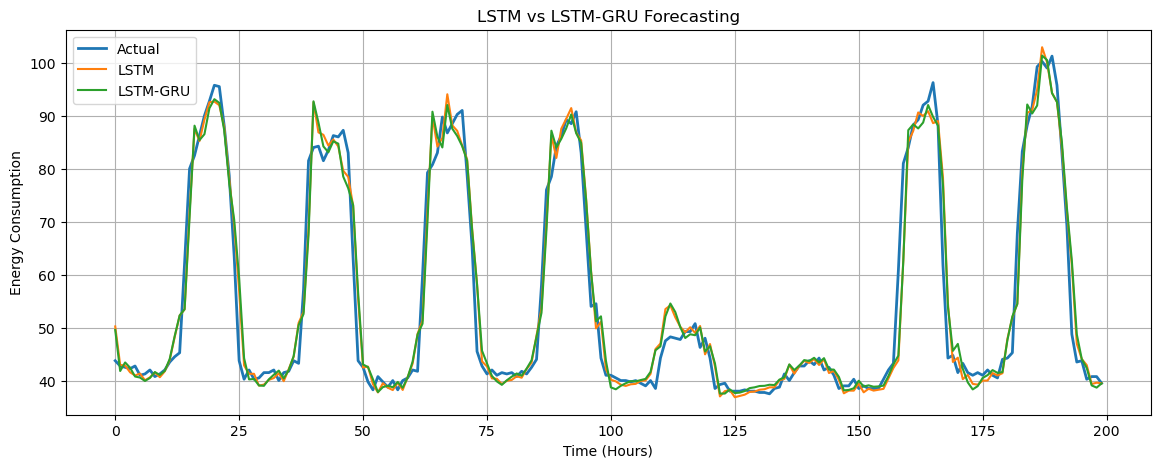

In [67]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_actual[:200],
    label='Actual',
    linewidth=2
)

plt.plot(
    lstm_predictions[:200],
    label='LSTM'
)

plt.plot(
    y_pred[:200],
    label='LSTM-GRU'
)

plt.title("LSTM vs LSTM-GRU Forecasting")

plt.xlabel("Time (Hours)")
plt.ylabel("Energy Consumption")

plt.legend()
plt.grid()

plt.show()

In [69]:
print("LSTM-GRU Improvement")
print("----------------------------")

print(
    "MAE Improvement:",
    round((lstm_mae - lstm_gru_results[0]) / lstm_mae * 100, 2),
    "%"
)

print(
    "RMSE Improvement:",
    round((lstm_rmse - lstm_gru_results[1]) / lstm_rmse * 100, 2),
    "%"
)

print(
    "MAPE Improvement:",
    round((lstm_mape - lstm_gru_results[2]) / lstm_mape * 100, 2),
    "%"
)

LSTM-GRU Improvement
----------------------------
MAE Improvement: 6.12 %
RMSE Improvement: 5.76 %
MAPE Improvement: 4.71 %
